# Dermoscopy Copilot — 04. Copilot Application (Streamlit) and Retraining with Clinician Corrections

**Course:** Human-Centered Artificial Intelligence (HCAI) · MSc in Biomedical Engineering · University of Coimbra
**Group 13:** Carolina Garrido, Sara Santos, Sara Seco

## Purpose of this notebook

This is the last phase of the project: the **human-centered layer** placed on top of the **final active learning model**. It is an interactive **Streamlit application** in which a clinician uploads a dermoscopic image, sees the prediction, its confidence and a heatmap, and decides whether to accept or correct it. The final decision always belongs to the clinician: the system is a decision-support tool, not an autonomous diagnostic tool.

This notebook documents and demonstrates the three files of this phase:

| File | Role |
|---|---|
| `copilot_common.py` | Shared module: paths, frozen backbone and transformations (identical to notebook 02), TTA views, loading of the model of the app (`al_head_retrained.pt`, the final active learning head retrained with the clinician's corrections) and temperature calibration |
| `app.py` | The Streamlit application: image upload → calibrated prediction with TTA ×8 → Grad-CAM heatmap → referral warning → accept/correct → log in a CSV file |
| `retrain_with_corrections.py` | Adds the images validated or corrected by the clinician to the images labelled by the active learning loop and updates the linear layer with **one more active learning cycle** |

A Streamlit app cannot run inside a notebook (it is launched with `streamlit run app.py`, see section 9). This notebook therefore **imports the shared module**, **reproduces the app's inference pipeline on one example image** to show what the clinician sees, **summarises the feedback log** and **loads the results of the retraining** if they exist. Nothing is retrained here.

### Human-centered design choices

| Component | Human-centered role |
|---|---|
| Referral rule | Decides when the clinician is *in the loop* (uncertain case or melanoma risk) and when the model only suggests, with the clinician *on the loop* |
| Grad-CAM heatmap | Transparency: shows which image regions support the prediction |
| Calibrated probabilities | Confidence values that the clinician can interpret |
| Accept / Correct buttons and CSV log | The clinician keeps the final decision and every decision is recorded |
| Retraining as one more active learning cycle | The model learns from the clinician's corrections and remains an active learning model |

**Prerequisites:** run this notebook from the **root of the repository** (where `copilot_common.py` is), with the features from notebook 02 in `features/`, the splits from notebook 01 in `splits/`, and the files created by `export_al_head.py` (`al_head.pt`, `al_labelled.npz` and `al_head_metrics.json`) and by `retrain_with_corrections.py` (`al_head_retrained.pt` and `retrained_metrics.json`) in `results/results_active_learning/`.

## 1. Library imports

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from PIL import Image

# Base path: go up one level if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")
# copilot_common.py lives in the repository root, so the root must be on the import path
sys.path.insert(0, str(BASE_DIR.resolve()))

from copilot_common import (AL_DIR, AL_LABELLED, AL_METRICS, CLASSES, FEATS, HEAD_PATH, IMG_DIR,
                            LOG_CSV, N_AUG, RESULTS, calibrate, device, load_backbone,
                            load_head, vistas_tta)

c:\Users\carol\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Shared module (`copilot_common.py`)

The module is shared by the app and by the retraining script, so that both use exactly the same backbone, transformations and calibration. It defines:

- **Paths:** features (`features/features_<BACKBONE>/`), the folder of the active learning results (`results/results_active_learning/`) and the folder `app_data/`, where the app stores the clinician's images and the feedback log (`feedback_log.csv`). The results of the passive baseline (`results/results_baseline/`) are kept only for comparison.
- **Model of the app:** `HEAD_PATH` points to `al_head_retrained.pt`, the **final active learning head** (`al_head.pt`, created by `export_al_head.py`) **retrained with the clinician's corrections** (section 8). `AL_LABELLED` (`al_labelled.npz`) holds the images labelled by the active learning loop and the labels given by the annotators, and `AL_METRICS` (`al_head_metrics.json`) the test metrics of that head.
- `load_backbone`: frozen `timm` backbone (without the classification layer) and the **same transformations as in notebook 02** (`base_tf` and `aug_tf`).
- `vistas_tta`: the 8 TTA views (4 rotations × horizontal flip), as in notebook 02.
- `load_head`: loads the trained linear layer from `HEAD_PATH`.
- `fit_temperature` and `calibrate`: temperature scaling, as in `referral.py`. `T` is fitted on the validation features (with TTA) by minimising the negative log-likelihood with L-BFGS, over the **mean of the logits of the 8 views**. The temperature is computed when the app starts, and it can differ slightly from the one saved in the checkpoints, which is fitted over the mean of the probabilities of the views.

The cell below checks which of the expected files and folders exist.

In [2]:
for name, p in [("Features", FEATS),
                ("Active learning results", AL_DIR),
                ("Model of the app", HEAD_PATH),
                ("Labelled images (AL)", AL_LABELLED),
                ("Head metrics (AL)", AL_METRICS),
                ("Passive baseline", RESULTS),
                ("Clinician images", IMG_DIR),
                ("Feedback log", LOG_CSV)]:
    print(f"{name:24s} {p}  ->  {'found' if p.exists() else 'NOT found'}")

Features                 C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\features\features_tf_efficientnetv2_s.in21k_ft_in1k  ->  found
Active learning results  C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_active_learning  ->  found
Model of the app         C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_active_learning\al_head_retrained.pt  ->  found
Labelled images (AL)     C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_active_learning\al_labelled.npz  ->  found
Head metrics (AL)        C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_active_learning\al_head_metrics.json  ->  found
Passive baseline         C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_baseline\results_tf_efficientnetv2_s.in21k_ft_in1k  ->  found
Clinician images         C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\app_data\images  ->  found
Feedback log             C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\app_data\f

## 3. Loading the calibrated model

As the app does at start-up (`load_all`), the frozen backbone, the model of the app (the retrained active learning head) and the temperature `T` are loaded. The backbone weights are read from the `timm` cache, and `T` is computed from the validation features, so this step takes a few seconds but trains nothing.

The test metrics of the retrained head (`retrained_metrics.json`) and of the active learning head before the retraining (`al_head_metrics.json`) are then shown next to those of the passive baseline, as a reference for the model that the clinician will be using.

In [3]:
bb, base_tf, aug_tf, size = load_backbone()
head = load_head()
T = calibrate(head)

print(f"Device: {device} | input size: {size}")
print(f"Model of the app: {HEAD_PATH}")
print(f"Linear layer: {head}")
print(f"Calibration temperature (validation, mean of the 8 view logits): T = {T:.3f}")

keys = ["f1_macro", "balanced_acc", "recall_melanoma"]
ref = {}
if (AL_DIR / "retrained_metrics.json").exists():
    with open(AL_DIR / "retrained_metrics.json", encoding="utf-8") as f:
        re_m = json.load(f)
    ref["retrained head (app)"] = {k: re_m[k] for k in keys}
if AL_METRICS.exists():
    with open(AL_METRICS, encoding="utf-8") as f:
        al_m = json.load(f)
    ref["active learning head"] = {k: al_m[k] for k in keys}
if (RESULTS / "baseline_metrics.json").exists():
    with open(RESULTS / "baseline_metrics.json", encoding="utf-8") as f:
        base = json.load(f)
    ref["passive baseline"] = {k: base[k] for k in keys}
if ref:
    print("\nTest metrics (with TTA):")
    display(pd.DataFrame(ref).round(4))

Device: cpu | input size: 300
Model of the app: C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\results\results_active_learning\al_head_retrained.pt
Linear layer: Linear(in_features=1280, out_features=7, bias=True)
Calibration temperature (validation, mean of the 8 view logits): T = 1.059

Test metrics (with TTA):


,retrained head (app),active learning head,passive baseline
f1_macro,0.6144,0.5932,0.6227
balanced_acc,0.6102,0.5988,0.6373
recall_melanoma,0.6101,0.5912,0.6918


## 4. Referral rule

The app applies the rule defined in `referral.py`: a case is **sent to the human** (human in the loop) if the confidence of the model is below `CONF_X` **or** the probability of melanoma is at least `MEL_RISK_THR` (20%). Otherwise, the prediction is shown as a suggestion under the supervision of the clinician (human on the loop).

The second condition reflects the clinical cost of false negatives in melanoma, which is the focus of the sensitivity analysis in the proposal.

In [4]:
CONF_X = 0.80          
MEL_RISK_THR = 0.20
MEL_IDX = CLASSES.index("mel")


def needs_human(probs):
    # Low confidence OR melanoma risk -> human in the loop
    # (in app.py this condition is written inline)
    return bool(probs.max() < CONF_X or probs[MEL_IDX] >= MEL_RISK_THR)

## 5. Prediction and heatmap (`app.py`)

The two functions below are the ones used by the app, without changes.

- `predict`: the image is transformed with `base_tf`, the 8 TTA views go through the backbone and the linear layer, the logits are averaged over the views and divided by the temperature `T` before the softmax. It also returns the feature maps `A` of the **original view**, used for the heatmap.
- `cam_overlay`: **class activation map** of the predicted class of the same model. Because the classifier is a single linear layer applied to globally pooled features, Grad-CAM has a closed form: each channel of `A` is weighted by the weight that the linear layer gives to the predicted class (`head.weight[pred]`), the sum over channels goes through a ReLU, is resized to the input size, normalised to [0, 1] and overlaid on the image (55% image, 45% colour map).

In [5]:
@torch.no_grad()
def predict(pil):
    x = base_tf(pil).unsqueeze(0).to(device)
    feats = bb(torch.cat(vistas_tta(x))).float()                  # (8, D)
    logits = head(feats).mean(0)                                  # mean of the logits of the 8 views
    probs = torch.softmax(logits / T, dim=0).cpu().numpy()
    A = bb.forward_features(x).float()                            # (1, C, h, w), original view
    return probs, A


@torch.no_grad()
def cam_overlay(A, pred, pil):
    cam = torch.relu(torch.einsum("bchw,c->bhw", A, head.weight[pred]))
    cam = F.interpolate(cam[:, None], size=(size, size), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam / cam.max().clamp_min(1e-8)).cpu().numpy()
    img = np.asarray(pil.resize((size, size))).astype(np.float32) / 255.0
    return (0.55 * img + 0.45 * cm.jet(cam)[..., :3]).clip(0, 1)

## 6. Example: what the clinician sees

The pipeline is applied to one image. By default, the first image saved by the app in `app_data/images/` is used; if there is none, a melanoma image of the test split is taken from the HAM10000 dataset (cached by `kagglehub`). To try another image, set `EXAMPLE_IMAGE` to its path.

The figure reproduces the three elements of the app: the image, the heatmap of the predicted class and the probability of each class. The messages below it are the ones shown by the app.

Image: C:\Users\carol\Desktop\UC\Mestrado\IACH\Trabalho\app_data\images\1795711169_ISIC_0026916.jpg


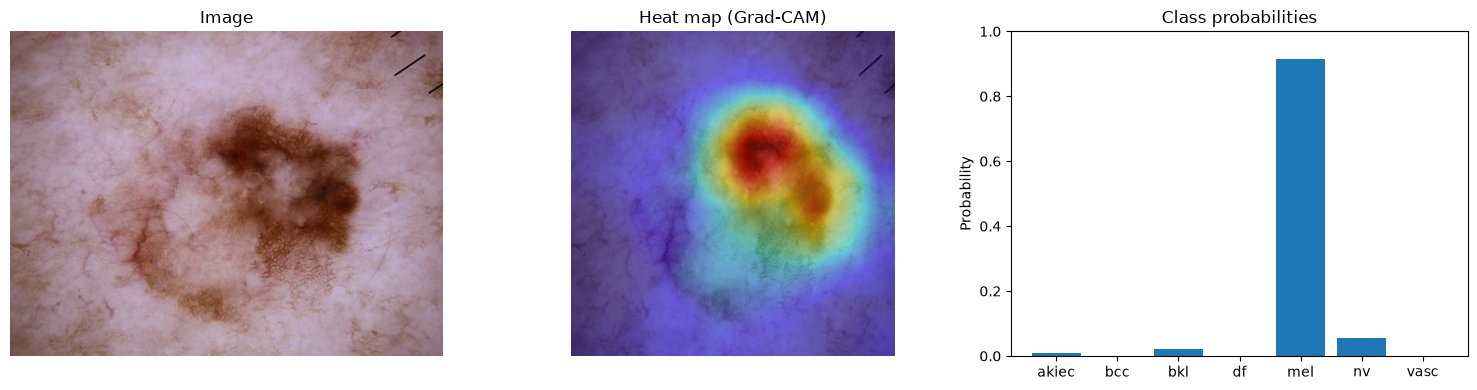

Predicted class: mel — confidence 91.4%
P(melanoma) = 91.4%
⚠️ Uncertain case, review needed. Sent to a human (human in the loop).


In [6]:
EXAMPLE_IMAGE = None   # path of an image to try (None = automatic choice)

true_label = None
if EXAMPLE_IMAGE is not None:
    img_path = Path(EXAMPLE_IMAGE)
else:
    imgs = sorted(p for p in IMG_DIR.glob("*")
                  if p.suffix.lower() in {".jpg", ".jpeg", ".png"}) if IMG_DIR.exists() else []
    if imgs:
        img_path = imgs[0]
    else:
        import kagglehub
        path_img = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
        test = pd.read_csv(BASE_DIR / "splits" / "test.csv")
        row = test[test["dx"] == "mel"].iloc[0]
        img_path = next(Path(path_img).glob(f"*/{row['image_id']}.jpg"))
        true_label = row["dx"]
print("Image:", img_path)

pil = Image.open(img_path).convert("RGB")
probs, A = predict(pil)
pred = int(probs.argmax())
human = needs_human(probs)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(pil)
axes[0].set_title("Image")
axes[0].axis("off")
axes[1].imshow(cam_overlay(A, pred, pil))
axes[1].set_title("Heat map (Grad-CAM)")
axes[1].axis("off")
axes[2].bar(CLASSES, probs)
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("Probability")
axes[2].set_title("Class probabilities")
plt.tight_layout()
plt.show()

print(f"Predicted class: {CLASSES[pred]} — confidence {probs[pred]:.1%}")
print(f"P(melanoma) = {probs[MEL_IDX]:.1%}")
if human:
    print("⚠️ Uncertain case, review needed. Sent to a human (human in the loop).")
else:
    print("Model suggestion, under clinician supervision (human on the loop).")
if true_label is not None:
    print(f"Ground truth (HAM10000): {true_label}")

## 7. Clinician feedback log

In the app, the clinician either **accepts** the prediction or **corrects** it by choosing the right class. Each decision saves the image in `app_data/images/` and adds one row to `app_data/feedback_log.csv`:

| Column | Content |
|---|---|
| `timestamp`, `image_file` | When the decision was made and the saved image |
| `pred_class`, `confidence`, `mel_prob` | What the model predicted, with its confidence and the probability of melanoma |
| `sent_to_human` | 1 if the referral rule sent the case to the human |
| `action`, `final_label` | `accepted` or `corrected`, and the label chosen by the clinician |
| `disagreement` | 1 if the final label differs from the prediction |

The cell below summarises the log, if it exists. The cross-table shows whether the disagreements happen mainly in the cases that the referral rule sent to the human.

In [7]:
if LOG_CSV.exists():
    log = pd.read_csv(LOG_CSV)
    display(log.tail())

    summary = pd.Series({
        "decisions logged": len(log),
        "accepted": int((log["action"] == "accepted").sum()),
        "corrected": int((log["action"] == "corrected").sum()),
        "sent to the human (referral rule)": int(log["sent_to_human"].sum()),
        "disagreements with the model": int(log["disagreement"].sum()),
    })
    display(summary.to_frame("count"))

    print("Sent to the human (rows) vs disagreement with the model (columns):")
    display(pd.crosstab(log["sent_to_human"], log["disagreement"]))
else:
    print("No feedback log yet: run the app and save at least one decision.")

,timestamp,image_file,pred_class,confidence,mel_prob,sent_to_human,action,final_label,disagreement
16,2026-11-26 16:52:25,1795711945_ISIC_0034011.jpg,bkl,0.8985,0.0263,0,accepted,bkl,0
17,2026-11-26 16:53:01,1795711981_ISIC_0034087.jpg,nv,0.7042,0.0809,1,corrected,mel,1
18,2026-11-26 16:53:39,1795712019_ISIC_0033586.jpg,nv,0.6740,0.2573,1,corrected,mel,1
19,2026-11-26 16:54:21,1795712061_ISIC_0033780.jpg,df,0.9995,0.0003,0,accepted,df,0
20,2026-11-26 16:54:43,1795712083_ISIC_0034196.jpg,vasc,0.9927,0.0025,0,accepted,vasc,0


,count
decisions logged,21
accepted,15
corrected,6
sent to the human (referral rule),4
disagreements with the model,6


Sent to the human (rows) vs disagreement with the model (columns):


disagreement,0,1
sent_to_human,,
0,13,4
1,2,2


## 8. Retraining with the clinician's corrections (`retrain_with_corrections.py`)

The update is **one more active learning cycle**, not a retraining from scratch:

- **Starting point:** always the final active learning head (`al_head.pt`), whose weights are loaded and then continued, not random weights (not `HEAD_PATH`, which points to the retrained head).
- **Labelled data:** only the images labelled by the active learning loop (`al_labelled.npz`, with the labels given by the annotators, which can differ from the true labels when the oracle is noisy) plus the images of the clinician, **not the whole training set**, so the model remains an active learning model. Each new image enters as the **original plus `N_AUG` augmented copies**, with the label chosen by the clinician (`final_label`).
- **Training:** the same `LinearHead.fit` used by `ActiveLearner.teach` in `active_learning.py` (3 epochs, class weights, Adam, no early stopping).
- **Calibration and evaluation:** temperature scaling fitted on the validation set, and evaluation on the **same test set** with TTA.
- **Comparison:** with the active learning head before the retraining (`al_head_metrics.json`), not with the passive baseline.

It is run from the root of the repository with `python retrain_with_corrections.py`. It does **not overwrite** `al_head.pt`: it saves the new layer (`al_head_retrained.pt`, overwritten at every run) and its metrics (`retrained_metrics.json`) in `results/results_active_learning/`. The app uses the retrained head, because `HEAD_PATH` in `copilot_common.py` points to it. This notebook does not retrain: the cells below show the images labelled by the active learning loop and load the saved metrics, if they exist.

> **Note:** the validation and test sets are not changed, and the number of images collected by the clinician is small, so differences are expected to be small. They should be interpreted with caution.

In [8]:
if AL_LABELLED.exists():
    al = np.load(AL_LABELLED, allow_pickle=True)
    al_ids = al["image_ids"].astype(str)
    given = pd.Series(al["labels"]).map(dict(enumerate(CLASSES)))
    print(f"Images labelled by the active learning loop: {len(np.unique(al_ids))}")
    print("Labels given by the annotators:")
    display(given.value_counts().to_frame("images"))
else:
    print("al_labelled.npz not found: run export_al_head.py first.")

Images labelled by the active learning loop: 3715
Labels given by the annotators:


,images
nv,1991
mel,609
bkl,583
bcc,247
akiec,184
df,65
vasc,36


In [9]:
RETRAINED_METRICS = AL_DIR / "retrained_metrics.json"

if AL_METRICS.exists() and RETRAINED_METRICS.exists():
    with open(AL_METRICS, encoding="utf-8") as f:
        before = json.load(f)
    with open(RETRAINED_METRICS, encoding="utf-8") as f:
        after = json.load(f)

    keys = ["f1_macro", "balanced_acc", "recall_melanoma"]
    comp = pd.DataFrame({"before": [before[k] for k in keys],
                         "after": [after[k] for k in keys]}, index=keys)
    comp["difference"] = comp["after"] - comp["before"]

    print(f"New images used in retraining: {after['n_new_images']}")
    display(comp.round(4))
else:
    print("No retraining results yet: after collecting corrections, run "
          "`python retrain_with_corrections.py` from the root of the repository.")

New images used in retraining: 21


,before,after,difference
f1_macro,0.5932,0.6144,0.0212
balanced_acc,0.5988,0.6102,0.0114
recall_melanoma,0.5912,0.6101,0.0189


## 9. Running the application

From the root of the repository, with the active learning head already exported (`export_al_head.py`, which creates `al_head.pt`, `al_labelled.npz` and `al_head_metrics.json`), the retrained head (`retrain_with_corrections.py`, which creates `al_head_retrained.pt`) and the features available:

```bash
pip install streamlit
streamlit run app.py
```

The first run downloads the weights of the backbone. In the browser, the clinician uploads an image, reads the prediction, the confidence and the heatmap, and then accepts or corrects the prediction. Every decision is added to `app_data/feedback_log.csv` and can later be used by `retrain_with_corrections.py`.